Acoustic_PS
Week 1 – Audio Fundamentals & Feature Exploration
Base Paper: USEF-TSE

In [ ]:
!pip -q install librosa torchaudio soundfile scikit-learn fastdtw tqdm

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display
import soundfile as sf
import torch
import torchaudio

from tqdm import tqdm
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.manifold import TSNE
from scipy.spatial.distance import euclidean

print("Libraries loaded successfully.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.4/133.4 kB 4.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
Libraries loaded successfully.


In [ ]:
AUDIO_PATH = "/content/61-70968-0000_8455-210777-0012.wav"

audio, sr = librosa.load(AUDIO_PATH, sr=None, mono=True)

print("Sample rate:", sr)
print("Samples:", len(audio))
print("Duration:", len(audio) / sr, "seconds")

Sample rate: 16000
Samples: 56400
Duration: 3.525 seconds


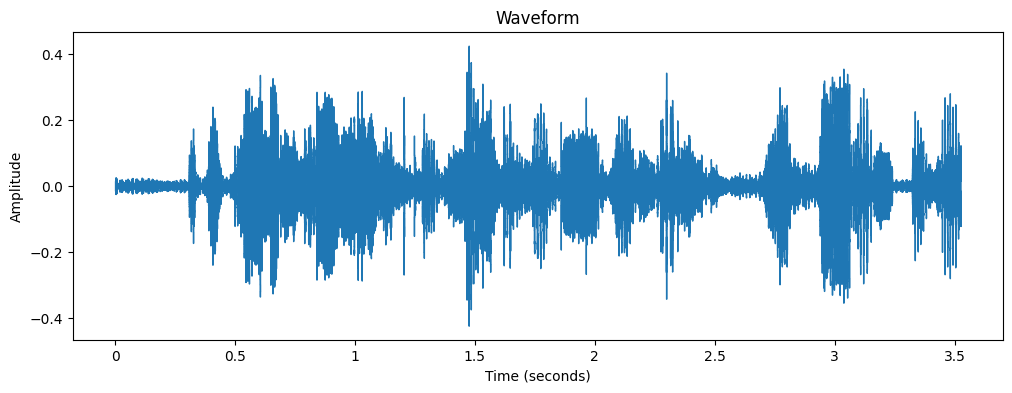

In [ ]:
plt.figure(figsize=(12, 4))

librosa.display.waveshow(audio, sr=sr)

plt.title("Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.show()

In [ ]:
n_fft = 1024
hop_length = 256

stft = librosa.stft(
    audio,
    n_fft=n_fft,
    hop_length=hop_length
)

magnitude = np.abs(stft)

print("STFT shape:", stft.shape)
print("Magnitude shape:", magnitude.shape)

STFT shape: (513, 221)
Magnitude shape: (513, 221)


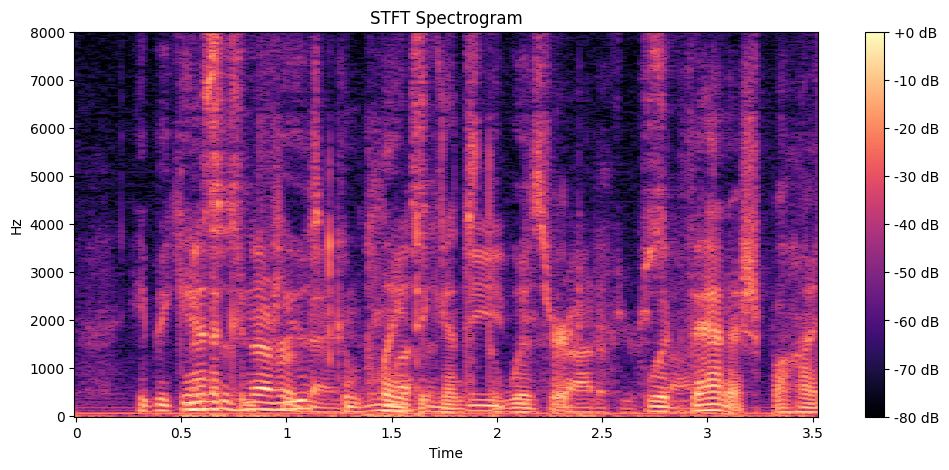

In [ ]:
db = librosa.amplitude_to_db(
    magnitude,
    ref=np.max
)

plt.figure(figsize=(12, 5))

librosa.display.specshow(
    db,
    sr=sr,
    hop_length=hop_length,
    x_axis="time",
    y_axis="hz"
)

plt.colorbar(format="%+2.0f dB")
plt.title("STFT Spectrogram")
plt.show()

In [ ]:
settings = [
    (512, 128),
    (1024, 256),
    (2048, 512)
]

for n_fft, hop_length in settings:

    stft = librosa.stft(
        audio,
        n_fft=n_fft,
        hop_length=hop_length
    )

    print(
        f"n_fft={n_fft}, hop_length={hop_length}, "
        f"shape={stft.shape}"
    )

n_fft=512, hop_length=128, shape=(257, 441)
n_fft=1024, hop_length=256, shape=(513, 221)
n_fft=2048, hop_length=512, shape=(1025, 111)


In [ ]:
n_mels = 128

mel = librosa.feature.melspectrogram(
    y=audio,
    sr=sr,
    n_fft=1024,
    hop_length=256,
    n_mels=n_mels
)

mel_db = librosa.power_to_db(
    mel,
    ref=np.max
)

print("Mel-spectrogram shape:", mel.shape)

Mel-spectrogram shape: (128, 221)


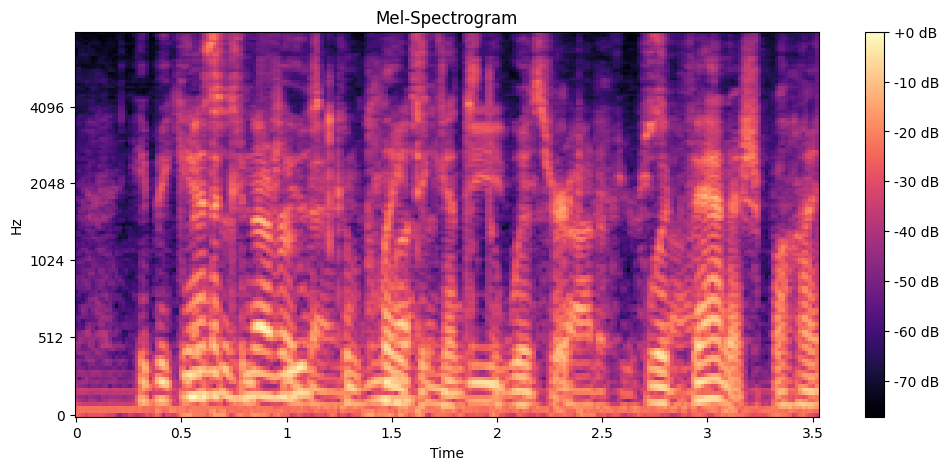

In [ ]:
plt.figure(figsize=(12, 5))

librosa.display.specshow(
    mel_db,
    sr=sr,
    hop_length=256,
    x_axis="time",
    y_axis="mel"
)

plt.colorbar(format="%+2.0f dB")
plt.title("Mel-Spectrogram")
plt.show()

In [ ]:
cqt = librosa.cqt(
    audio,
    sr=sr,
    hop_length=256
)

cqt_db = librosa.amplitude_to_db(
    np.abs(cqt),
    ref=np.max
)

print("CQT shape:", cqt.shape)

CQT shape: (84, 221)


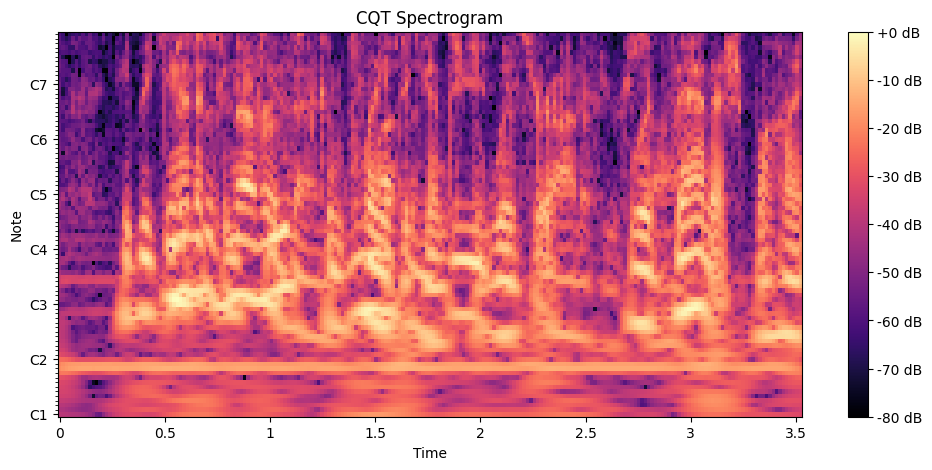

In [ ]:
plt.figure(figsize=(12, 5))

librosa.display.specshow(
    cqt_db,
    sr=sr,
    hop_length=256,
    x_axis="time",
    y_axis="cqt_note"
)

plt.colorbar(format="%+2.0f dB")
plt.title("CQT Spectrogram")
plt.show()

In [ ]:
project_root = "/content/USEF-TSE-Project"

folders = [
    "data/raw",
    "data/processed",
    "data/splits",
    "src",
    "notebooks",
    "results/figures",
    "results/metrics",
    "docs"
]

for folder in folders:
    os.makedirs(
        os.path.join(project_root, folder),
        exist_ok=True
    )

print("Project structure created:")

Project structure created:


In [ ]:
for root, dirs, files in os.walk(project_root):
    level = root.replace(project_root, "").count(os.sep)
    indent = "  " * level
    print(indent + os.path.basename(root) + "/")

USEF-TSE-Project/
  data/
    raw/
    processed/
    splits/
  src/
  notebooks/
  docs/
  results/
    metrics/
    figures/


In [ ]:
DATA_DIR = "/content/audio_dataset"

In [ ]:
wav_files = glob.glob(
    os.path.join(DATA_DIR, "**", "*.wav"),
    recursive=True
)

print("Number of WAV files:", len(wav_files))

for f in wav_files[:10]:
    print(f)

Number of WAV files: 10
/content/audio_dataset/61-70968-0000_8555-292519-0000.wav
/content/audio_dataset/61-70968-0010_3575-170457-0003.wav
/content/audio_dataset/61-70968-0005_1284-1180-0015.wav
/content/audio_dataset/61-70968-0003_2830-3980-0008.wav
/content/audio_dataset/61-70968-0009_4446-2271-0011.wav
/content/audio_dataset/61-70968-0004_1188-133604-0014.wav
/content/audio_dataset/61-70968-0003_2961-960-0017.wav
/content/audio_dataset/61-70968-0005_5105-28233-0000.wav
/content/audio_dataset/61-70968-0003_5105-28240-0000.wav
/content/audio_dataset/61-70968-0007_7176-88083-0021.wav


In [ ]:
records = []

for path in tqdm(wav_files):

    try:
        info = sf.info(path)

        records.append({
            "filename": os.path.basename(path),
            "path": path,
            "sample_rate": info.samplerate,
            "channels": info.channels,
            "frames": info.frames,
            "duration_s": info.duration,
            "format": info.format,
            "subtype": info.subtype,
            "valid": True
        })

    except Exception as e:

        records.append({
            "filename": os.path.basename(path),
            "path": path,
            "valid": False,
            "error": str(e)
        })

df = pd.DataFrame(records)

df.head()

100%|██████████| 10/10 [00:00<00:00, 3497.29it/s]


,filename,path,sample_rate,channels,frames,duration_s,format,subtype,valid
0,61-70968-0000_8555-292519-0000.wav,/content/audio_dataset/61-70968-0000_8555-2925...,16000,1,78480,4.905,WAV,PCM_16,True
1,61-70968-0010_3575-170457-0003.wav,/content/audio_dataset/61-70968-0010_3575-1704...,16000,1,121520,7.595,WAV,PCM_16,True
2,61-70968-0005_1284-1180-0015.wav,/content/audio_dataset/61-70968-0005_1284-1180...,16000,1,81120,5.070,WAV,PCM_16,True
3,61-70968-0003_2830-3980-0008.wav,/content/audio_dataset/61-70968-0003_2830-3980...,16000,1,69040,4.315,WAV,PCM_16,True
4,61-70968-0009_4446-2271-0011.wav,/content/audio_dataset/61-70968-0009_4446-2271...,16000,1,63120,3.945,WAV,PCM_16,True


In [ ]:
if len(df) > 0:

    print("Minimum duration:",
          df["duration_s"].min())

    print("Maximum duration:",
          df["duration_s"].max())

    print("Average duration:",
          df["duration_s"].mean())

    print("\nFiles shorter than 4 seconds:",
          (df["duration_s"] < 4).sum())

Minimum duration: 3.55
Maximum duration: 7.595
Average duration: 4.6405

Files shorter than 4 seconds: 3


In [ ]:
print(
    df["sample_rate"].value_counts()
)

sample_rate
16000    10
Name: count, dtype: int64


In [ ]:
SEGMENT_DURATION = 4

segment_records = []

for path in tqdm(wav_files):

    try:

        waveform, sr = torchaudio.load(path)

        # Convert stereo to mono
        if waveform.shape[0] > 1:
            waveform = waveform.mean(dim=0, keepdim=True)

        segment_samples = int(
            SEGMENT_DURATION * sr
        )

        total_samples = waveform.shape[1]

        segment_id = 0

        for start in range(
            0,
            total_samples,
            segment_samples
        ):

            end = start + segment_samples

            segment = waveform[:, start:end]

            # Ignore extremely short final fragments
            if segment.shape[1] < 0.5 * segment_samples:
                continue

            segment_records.append({
                "source_file": os.path.basename(path),
                "segment_id": segment_id,
                "start_sample": start,
                "end_sample": min(end, total_samples),
                "sample_rate": sr,
                "duration_s": segment.shape[1] / sr
            })

            segment_id += 1

    except Exception as e:
        print("Error:", path, e)

segments_df = pd.DataFrame(segment_records)

print("Total segments:", len(segments_df))

segments_df.head()

100%|██████████| 10/10 [00:00<00:00, 96.52it/s]

Total segments: 11


,source_file,segment_id,start_sample,end_sample,sample_rate,duration_s
0,61-70968-0000_8555-292519-0000.wav,0,0,64000,16000,4.000
1,61-70968-0010_3575-170457-0003.wav,0,0,64000,16000,4.000
2,61-70968-0010_3575-170457-0003.wav,1,64000,121520,16000,3.595
3,61-70968-0005_1284-1180-0015.wav,0,0,64000,16000,4.000
4,61-70968-0003_2830-3980-0008.wav,0,0,64000,16000,4.000


In [ ]:
feature_vectors = []
feature_names = []

for path in tqdm(wav_files):

    try:

        y, sr = librosa.load(
            path,
            sr=None,
            mono=True
        )

        mfcc = librosa.feature.mfcc(
            y=y,
            sr=sr,
            n_mfcc=20
        )

        feature = np.concatenate([
            mfcc.mean(axis=1),
            mfcc.std(axis=1)
        ])

        feature_vectors.append(feature)
        feature_names.append(
            os.path.basename(path)
        )

    except Exception as e:
        print("Error:", path, e)

X = np.array(feature_vectors)

print("Feature matrix shape:", X.shape)

100%|██████████| 10/10 [00:00<00:00, 106.21it/s]

Feature matrix shape: (10, 40)


Cosine similarity matrix shape: (10, 10)


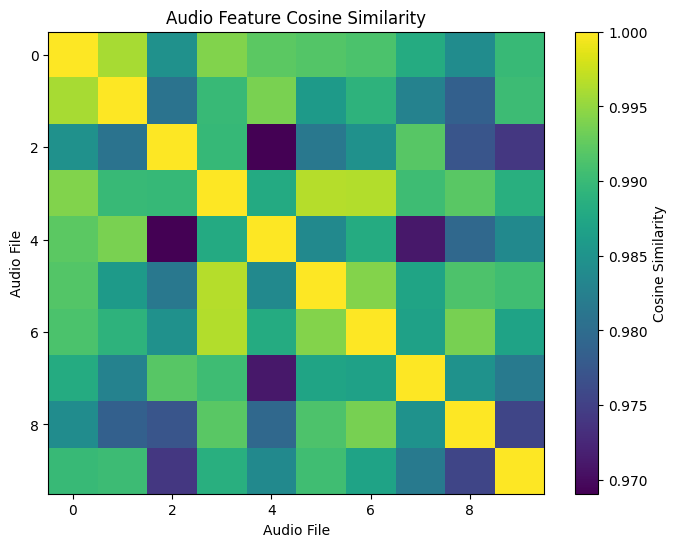

In [ ]:
if len(X) >= 2:

    similarity_matrix = cosine_similarity(X)

    print(
        "Cosine similarity matrix shape:",
        similarity_matrix.shape
    )

    plt.figure(figsize=(8, 6))

    plt.imshow(
        similarity_matrix,
        aspect="auto"
    )

    plt.colorbar(
        label="Cosine Similarity"
    )

    plt.title(
        "Audio Feature Cosine Similarity"
    )

    plt.xlabel("Audio File")
    plt.ylabel("Audio File")

    plt.show()

Higher value → more similar feature patterns
Lower value  → less similar feature patterns

In [ ]:
from librosa.sequence import dtw

dtw_features = []

for path in tqdm(wav_files[:10]):

    try:

        y, sr = librosa.load(
            path,
            sr=None,
            mono=True
        )

        # Limit length for exploratory DTW
        y = y[:min(len(y), sr * 3)]

        mfcc = librosa.feature.mfcc(
            y=y,
            sr=sr,
            n_mfcc=13
        )

        dtw_features.append(
            (os.path.basename(path), mfcc)
        )

    except Exception as e:
        print("Error:", path, e)

100%|██████████| 10/10 [00:00<00:00, 79.36it/s]


In [ ]:
n = len(dtw_features)

dtw_matrix = np.zeros((n, n))

for i in range(n):

    for j in range(i, n):

        name_i, feat_i = dtw_features[i]
        name_j, feat_j = dtw_features[j]

        D, wp = dtw(
            X=feat_i,
            Y=feat_j,
            metric="euclidean"
        )

        distance = D[-1, -1]

        dtw_matrix[i, j] = distance
        dtw_matrix[j, i] = distance

print("DTW matrix shape:", dtw_matrix.shape)

DTW matrix shape: (10, 10)


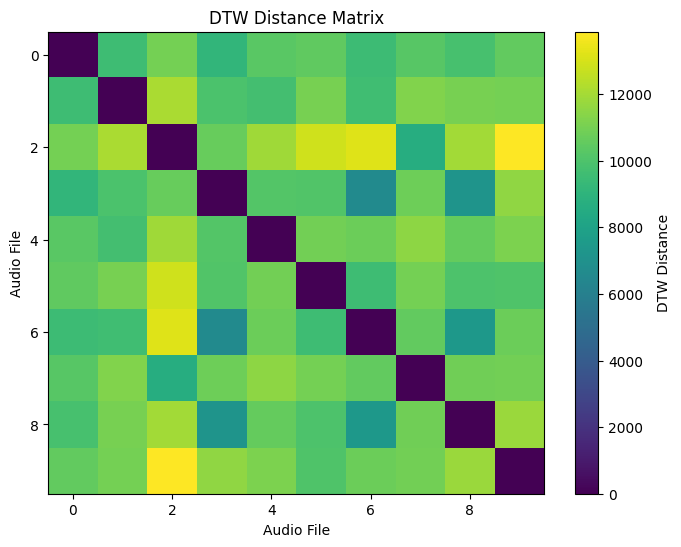

In [ ]:
plt.figure(figsize=(8, 6))

plt.imshow(
    dtw_matrix,
    aspect="auto"
)

plt.colorbar(
    label="DTW Distance"
)

plt.title(
    "DTW Distance Matrix"
)

plt.xlabel("Audio File")
plt.ylabel("Audio File")

plt.show()

Lower DTW distance → more similar temporal patterns
Higher DTW distance → less similar

In [ ]:
if len(X) >= 3:

    perplexity = min(
        5,
        len(X) - 1
    )

    tsne = TSNE(
        n_components=2,
        perplexity=perplexity,
        random_state=42
    )

    X_2d = tsne.fit_transform(X)

    print("t-SNE shape:", X_2d.shape)

t-SNE shape: (10, 2)


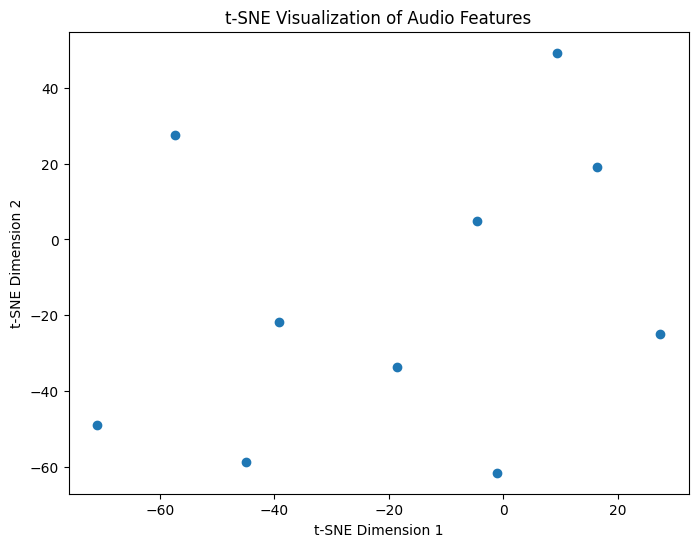

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_2d[:, 0],
    X_2d[:, 1]
)

plt.title(
    "t-SNE Visualization of Audio Features"
)

plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")

plt.show()

Points close together

        ↓
Similar feature patterns

--------------------------
Points far apart

        ↓
Different feature patterns

In [ ]:
results_dir = os.path.join(
    project_root,
    "results"
)

os.makedirs(results_dir, exist_ok=True)

if len(df) > 0:
    df.to_csv(
        os.path.join(
            results_dir,
            "audio_validation.csv"
        ),
        index=False
    )

if len(X) > 0:
    np.save(
        os.path.join(
            results_dir,
            "audio_features.npy"
        ),
        X
    )

if len(X) >= 2:
    np.save(
        os.path.join(
            results_dir,
            "cosine_similarity.npy"
        ),
        similarity_matrix
    )

if len(dtw_features) > 0:
    np.save(
        os.path.join(
            results_dir,
            "dtw_matrix.npy"
        ),
        dtw_matrix
    )

print("Results saved.")

Results saved.


☑ Audio Fundamentals & Playboard Setup
-------------------------------------------
    ☑ Environment installed
    ☑ WAV loaded
    ☑ Audio played
    ☑ Waveform plotted
    ☑ Sample rate checked


☑ Audio Representation & Display
-------------------------------------------

    ☑ STFT
    ☑ Spectrogram
    ☑ Mel-spectrogram
    ☑ CQT
    ☑ n_fft experiment
    ☑ hop_length experiment

☑ SDLC & Repository Setup
-------------------------------------------

    ☑ Project folders created
    ⬜ GitHub repository connected
    ⬜ Tracking board created

☑ Bulk Data Pipeline
-------------------------------------------

    ☑ File indexing code
    ☑ Validation
    ☑ Duration checking
    ☑ Sample-rate checking
    ☑ Segmentation code
    ⬜ Actual 50+ file run, if 50+ files are not yet available

☑ Feature Exploration & Similarity
-------------------------------------------

    ☑ Feature extraction
    ☑ Cosine similarity
    ☑ DTW
    ☑ t-SNE